In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
import random
from PIL import Image
from tqdm.auto import tqdm
from typing import Dict, List, Tuple
from pathlib import Path
import cv2

device = 'cuda'if torch.cuda.is_available() else 'cpu'

In [6]:
#from google.colab import drive
#drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:


#data_dir = "/content/drive/MyDrive/GearedorNot"
#data_dir="/hackathon workshop/GearedorNot"
data_dir="GearedorNot"
data_transform = transforms.Compose([
    transforms.Resize(size=(224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

# creating tensor dataset from images
dataset = datasets.ImageFolder(root=data_dir,
                              transform=data_transform,
                              target_transform=None)

# get the names of our labels
class_names = dataset.classes

In [3]:
data_transform = transforms.Compose([
    transforms.Resize(size=(224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

# creating tensor dataset from images
dataset = datasets.ImageFolder(root=data_dir,
                              transform=data_transform,
                              target_transform=None)

# get the names of our labels
class_names = dataset.classes

In [4]:
len(dataset)

355

In [5]:
class_names

['Not Wearing Safety Gear', 'Wearing Safety Gear']

In [6]:
# train test split on our dataset
training_size = int(0.7 * len(dataset))
testing_size = len(dataset) - training_size

train_data, test_data = torch.utils.data.random_split(dataset, [training_size, testing_size])

print(f"images in training set: {len(train_data)}")
print(f"images in testing set: {len(test_data)}")
print(f"total images: {len(dataset)}")

images in training set: 248
images in testing set: 107
total images: 355


In [7]:
# creating dataloaders from train and test data
batch_size = 32

train_dataloader = DataLoader(dataset=train_data,
                              batch_size=batch_size,
                              num_workers=1,
                              shuffle=True)

test_dataloader = DataLoader(dataset=test_data,
                              batch_size=batch_size,
                              num_workers=1,
                              shuffle=False)

In [8]:
# using a pretrained vit model
vit_weights = torchvision.models.ViT_B_16_Weights.DEFAULT
vit = torchvision.models.vit_b_16(weights=vit_weights).to(device)

# freeze the base parameters
for parameter in vit.parameters():
    parameter.requires_grad = False

# set number of classes
vit.heads = nn.Linear(in_features=768, out_features=len(class_names)).to(device)

In [9]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(params=vit.parameters(),
                             lr=0.0001,
                             betas=(0.9, 0.999),
                            weight_decay=0.2)

In [10]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device) -> Tuple[float, float]:
    """Trains a PyTorch model for a single epoch
    """
    model.train()

    train_loss, train_acc = 0, 0

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # 1. forward pass
        y_pred = model(X)

        # 2. calculate loss
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        # 3. optimizer zero grad
        optimizer.zero_grad()

        # 4. loss backward
        loss.backward()

        # 5. optimizer step
        optimizer.step()

        # calculate and accumulate accuracy metric across all batches
        y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
        train_acc += (y_pred_class == y).sum().item()/len(y_pred)

    # average loss and accuracy per batch
    train_loss = train_loss / len(dataloader)
    train_acc = train_acc / len(dataloader)
    return train_loss, train_acc


In [13]:
def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module,
              device: torch.device) -> Tuple[float, float]:
    """tests a PyTorch model for a single epoch
    """
    # Put model in eval mode
    model.eval()

    # Setup test loss and test accuracy values
    test_loss, test_acc = 0, 0

    # Turn on inference context manager
    with torch.inference_mode():
        # Loop through DataLoader batches
        for batch, (X, y) in enumerate(dataloader):
            # Send data to target device
            X, y = X.to(device), y.to(device)

            # 1. Forward pass
            test_pred_logits = model(X)

            # 2. Calculate and accumulate loss
            loss = loss_fn(test_pred_logits, y)
            test_loss += loss.item()

            # Calculate and accumulate accuracy
            test_pred_labels = test_pred_logits.argmax(dim=1)
            test_acc += ((test_pred_labels == y).sum().item()/len(test_pred_labels))

    # Adjust metrics to get average loss and accuracy per batch
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

In [ ]:
def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module,
          epochs: int,
          device: torch.device) -> Dict[str, List]:
    """trains and tests a PyTorch model with train_step() and test_step()
    """
    # create empty results dictionary
    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": []
    }

    # set model on device
    model.to(device)

    # training and testing loop
    for epoch in tqdm(range(epochs)):
        train_loss, train_acc = train_step(model=model,
                                          dataloader=train_dataloader,
                                          loss_fn=loss_fn,
                                          optimizer=optimizer,
                                          device=device)
        test_loss, test_acc = test_step(model=model,
          dataloader=test_dataloader,
          loss_fn=loss_fn,
          device=device)

        # print loss and accuracy
        print(
          f"epoch: {epoch+1} | "
          f"train_loss: {train_loss:.4f} | "
          f"train_acc: {train_acc:.4f} | "
          f"test_loss: {test_loss:.4f} | "
          f"test_acc: {test_acc:.4f}"
        )

        # update results dictionary
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

    # Return the filled results at the end of the epochs
    return results

In [15]:
# trainig our model with train()
vit_results = train(model=vit,
                  train_dataloader=train_dataloader,
                  test_dataloader=test_dataloader,
                  optimizer=optimizer,
                  loss_fn=loss_fn,
                  epochs=10,
                  device=device)

  0%|          | 0/10 [00:00<?, ?it/s]

epoch: 1 | train_loss: 0.6502 | train_acc: 0.6406 | test_loss: 0.6316 | test_acc: 0.6967
epoch: 2 | train_loss: 0.5980 | train_acc: 0.7109 | test_loss: 0.5854 | test_acc: 0.7514
epoch: 3 | train_loss: 0.5501 | train_acc: 0.7826 | test_loss: 0.5423 | test_acc: 0.7827
epoch: 4 | train_loss: 0.5093 | train_acc: 0.8750 | test_loss: 0.5047 | test_acc: 0.8523
epoch: 5 | train_loss: 0.4729 | train_acc: 0.8984 | test_loss: 0.4654 | test_acc: 0.9148
epoch: 6 | train_loss: 0.4361 | train_acc: 0.9401 | test_loss: 0.4377 | test_acc: 0.9304
epoch: 7 | train_loss: 0.4065 | train_acc: 0.9596 | test_loss: 0.4095 | test_acc: 0.9382
epoch: 8 | train_loss: 0.3790 | train_acc: 0.9688 | test_loss: 0.3839 | test_acc: 0.9382
epoch: 9 | train_loss: 0.3564 | train_acc: 0.9805 | test_loss: 0.3647 | test_acc: 0.9609
epoch: 10 | train_loss: 0.3355 | train_acc: 0.9844 | test_loss: 0.3438 | test_acc: 0.9609


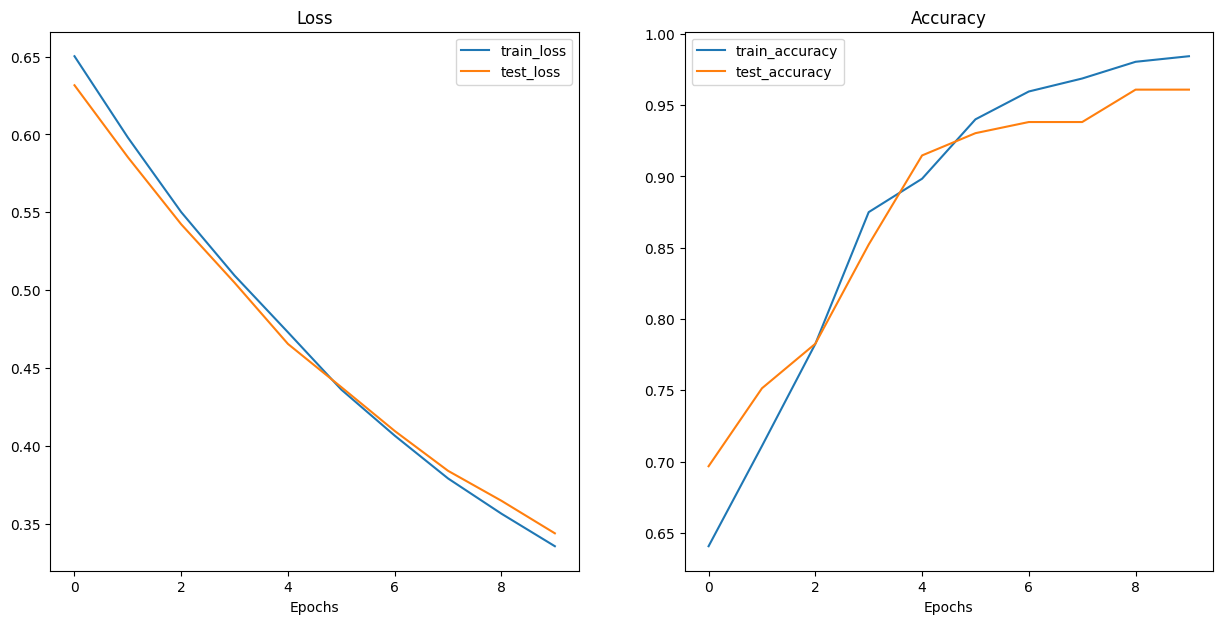

In [16]:
def plot_loss_curves(results):
    """plots training curves of a results dictionary
    """
    loss = results["train_loss"]
    test_loss = results["test_loss"]

    accuracy = results["train_acc"]
    test_accuracy = results["test_acc"]

    epochs = range(len(results["train_loss"]))

    plt.figure(figsize=(15, 7))

    # loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label="train_loss")
    plt.plot(epochs, test_loss, label="test_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()

    # accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label="train_accuracy")
    plt.plot(epochs, test_accuracy, label="test_accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epochs")
    plt.legend()

plot_loss_curves(vit_results)

In [20]:
#!pip install gradio 


[notice] A new release of pip is available: 24.1.1 -> 24.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from typing import List, Tuple
import torch
from PIL import Image
import torchvision.transforms as transforms

def pred_and_plot_image(model: torch.nn.Module,
                        image: Image.Image,
                        class_names: List[str],
                        image_size: Tuple[int, int] = (224, 224),
                        transform: torchvision.transforms = None,
                        device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")) -> int:
    """
    Make a prediction on a given image and return the predicted label.

    Args:
    - model: The trained Vision Transformer model.
    - image: A PIL image input.
    - class_names: A list of class names.
    - image_size: A tuple representing the size to resize the image to.
    - transform: Optional transformation to apply to the image.
    - device: The device to run the model on (CPU or GPU).

    Returns:
    - The predicted label index.
    """

    # set transformation
    if transform is not None:
        image_transform = transform
    else:
        image_transform = transforms.Compose([
            transforms.Resize(image_size),
            transforms.ToTensor()
        ])

    ### Predict on image ###

    # Set model to target device
    model.to(device)

    # Set model to evaluation mode
    model.eval()
    with torch.inference_mode():
        # Transform the image and add an extra batch dimension
        transformed_image = image_transform(image).unsqueeze(dim=0)

        # Predict on the transformed image
        target_image_pred = model(transformed_image.to(device))

        # Convert logits to probabilities with softmax function
        target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

        # Get the label with the highest probability
        target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    #return target_image_pred_label.item()
    return class_names[target_image_pred_label.item()]



In [ ]:
import gradio as gr


class_names = ["Person is not wearing Safety Equipment", "Person is wearing Hard Hat"]

# Define the input and output components
image_input = gr.Image(type='pil', height = 224, width = 224)



label_out = gr.Label(num_top_classes=2)
#print(label_out)
# Create the Gradio interface
interface = gr.Interface(
    fn=lambda img: pred_and_plot_image(vit, img, class_names, (224, 224)),
    inputs=image_input,
    outputs= label_out,
    allow_flagging="never",
    title="Safety Gear Identification",
    description="This app identifies if a person has worn safety gear or not",
    theme='soft',
)

# Launch the interface
interface.launch()
